# Lab 6 — Bidirectional RNN for Music Generation
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Big idea.** Treat a melody as a sequence of note *tokens*. A **two-layer Bidirectional LSTM**
reads the sequence and, at **every** time step, predicts the **next** note (a language-model
objective). After training we *generate* a new melody by predicting one note at a time and
sliding a window forward.

---
### How to use this notebook
Replace every `None  # TODO (Qn)` with the correct value or line of code. Run cells top to
bottom. Cells marked *(given — do not edit)* set things up for you.

> **Heads-up (you will analyse this):** the dataset here is *random* notes. Watch the accuracy
> and ask yourself in Task 7 whether it really means the model learned music.


## Step 0 — Imports *(given — do not edit)*

In [14]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(42); tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Build the dataset (next-token pairs)

We have `num_sequences` melodies, each `sequence_length` notes long, drawn from a vocabulary of
`num_notes` distinct notes. Turn each melody into an **(input, target)** pair where the target is
the input **shifted left by one** (predict the next note), then **one-hot encode** both.

*Hints:* the input is every note **except the last**; the target is every note **except the
first**. One-hot vectors have length `num_notes`.


In [15]:
num_notes       = 50     # vocabulary size (given)
sequence_length = 30     # notes per melody (given)
num_sequences   = 1000   # number of melodies (given)

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))  # (given)

# Q1a) input = all notes except the LAST;  target = all notes except the FIRST
x_train = data[:, :-1]   # TODO (Q1a): data[:, :-1]
y_train = data[:, 1:]   # TODO (Q1a): data[:, 1:]

# Q1b) one-hot encode both to shape (samples, 29, 50)
NUM_CLASSES = num_notes   # TODO (Q1b): how many distinct notes?
x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape, " y_train:", y_train.shape)   # expect (1000, 29, 50) each

x_train: (1000, 29, 50)  y_train: (1000, 29, 50)


#### Quick check *(given — run to verify Task 1)*

In [16]:
assert x_train.shape == (1000, 29, 50), "x_train shape should be (1000, 29, 50)"
assert y_train.shape == (1000, 29, 50), "y_train shape should be (1000, 29, 50)"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


## Task 2 — Build the Bidirectional LSTM model

Build a `Sequential` model with:
1. an **Input** of shape `(sequence_length-1, num_notes)` = `(29, 50)`;
2. **two Bidirectional LSTM layers**, 128 units each, **returning sequences** (an output at every
   step);
3. a **TimeDistributed Dense** output with `num_notes` units and **softmax** — one shared
   per-step note classifier.

*Hints:* a bidirectional layer is `layers.Bidirectional(layers.LSTM(units, return_sequences=...))`.
With 128 units per direction the layer outputs `2 * 128 = 256` features per step.


In [17]:
model = models.Sequential()
model.add(layers.Input(shape=(sequence_length-1, num_notes)))        # (29, 50)  (given)

# Q2a) first Bidirectional LSTM: 128 units, return a sequence
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))  # TODO (Q2a)

# Q2b) second Bidirectional LSTM: same settings
model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))   # TODO (Q2b): another Bidirectional(LSTM(128, return_sequences=True))

# Q2c) TimeDistributed Dense output: one softmax classifier per step
model.add(layers.TimeDistributed(layers.Dense(num_notes, activation='softmax')))  # TODO (Q2c)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_2 (Bidirectional) │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2d.** From the summary, the first Bi-LSTM shows **183,296** parameters. Verify
it by hand with `2 * 4 * [(features + units) * units + units]`, where `features = 50`,
`units = 128`. Then explain why the **second** Bi-LSTM has *more* parameters than the first.

> **Your answer (Q2d):** params = 2 × 4 × [ (____ + ____) × ____ + ____ ] = ________ ;
> the second layer is larger because ____.


## Task 3 — Compile and train

Compile with the **Adam** optimiser (learning rate `0.001`), **categorical crossentropy** loss
(targets are one-hot), and track **accuracy**. Train for 20 epochs, batch size 64, holding out
20% for validation.


In [18]:
# Q3a) compile for multi-class, one-hot targets
model.compile(optimizer=Adam(learning_rate=0.001),   # TODO (Q3a): 0.001
              loss='categorical_crossentropy',                             # TODO (Q3a): 'categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a 20% validation split
history = model.fit(x_train, y_train,
                    epochs=20,            # TODO (Q3b): 20
                    batch_size=64,        # TODO (Q3b): 64
                    validation_split=0.2)  # TODO (Q3b): 0.2

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 14s 434ms/step - accuracy: 0.1052 - loss: 3.8840 - val_accuracy: 0.1764 - val_loss: 3.8426
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 299ms/step - accuracy: 0.1437 - loss: 3.7714 - val_accuracy: 0.0917 - val_loss: 3.6519
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 422ms/step - accuracy: 0.1181 - loss: 3.5103 - val_accuracy: 0.1403 - val_loss: 3.3826
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 300ms/step - accuracy: 0.1628 - loss: 3.2059 - val_accuracy: 0.1853 - val_loss: 3.0892
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 303ms/step - accuracy: 0.2144 - loss: 2.8563 - val_accuracy: 0.2384 - val_loss: 2.7243
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 450ms/step - accuracy: 0.2811 - loss: 2.4622 - val_accuracy: 0.3055 - val_loss: 2.3186
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 298ms/step - accuracy: 0.3570 - loss: 2.0707 - val_accuracy: 0.3969 - val_loss: 1.9394
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 329ms/step - accuracy: 0.4467 - loss: 1.7070 - val_accuracy: 0

## Task 4 — Plot the training history *(fill the blanks)*

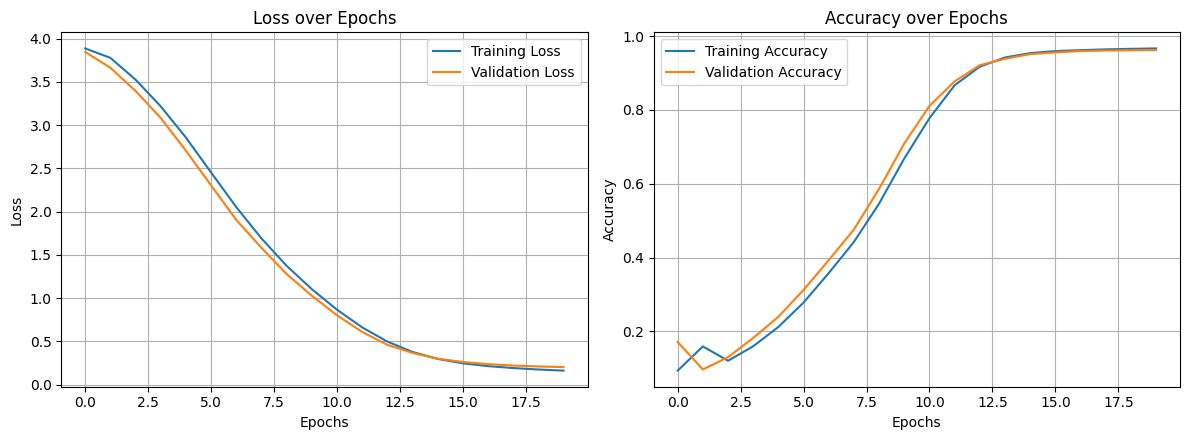

In [10]:
plt.figure(figsize=(12,4.5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'],     label='Training Loss')
plt.plot(history.history['val_loss'],       label='Validation Loss')   # TODO (Q4a): val loss key
plt.title('Loss over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'],       label='Validation Accuracy')  # TODO (Q4b): val acc key
plt.title('Accuracy over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid()

plt.tight_layout(); plt.show()

## Task 5 — Generate a new sequence (greedy decoding)

Complete the generation loop: predict with the model, read the distribution at the **last** time
step, take the most likely note (`argmax`), append it, then **slide the window** by dropping the
first step and appending the new note (one-hot).


In [11]:
def generate_music(model, start_sequence, num_generated_notes=50):
    generated = []
    current_sequence = start_sequence
    for _ in range(num_generated_notes):
        pred = model.predict(current_sequence, verbose=0)      # (1, 29, 50)

        # Q5a) pick the most likely note at the LAST time step
        next_note = np.argmax(pred[:, -1, :], axis=-1)   # TODO (Q5a): np.argmax(pred[:, -1, :], axis=-1)
        generated.append(int(next_note[0]))

        # Q5b) slide the window: drop the first step, append the new note (one-hot)
        oh = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)
        current_sequence = np.concatenate([current_sequence[:, 1:, :], oh], axis=1)   # TODO (Q5b): np.concatenate([current_sequence[:, 1:, :], oh], axis=1)
    return generated

# seed window (given)
start = np.random.randint(0, num_notes, size=(1, sequence_length-1))
start = to_categorical(start, num_classes=num_notes)

generated_music = generate_music(model, start, num_generated_notes=50)
print("Generated:", generated_music)

Generated: [10, 10, 10, 10, 17, 17, 17, 17, 17, 17, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5]


## Task 6 — Piano-roll of the generated melody *(fill one blank)*

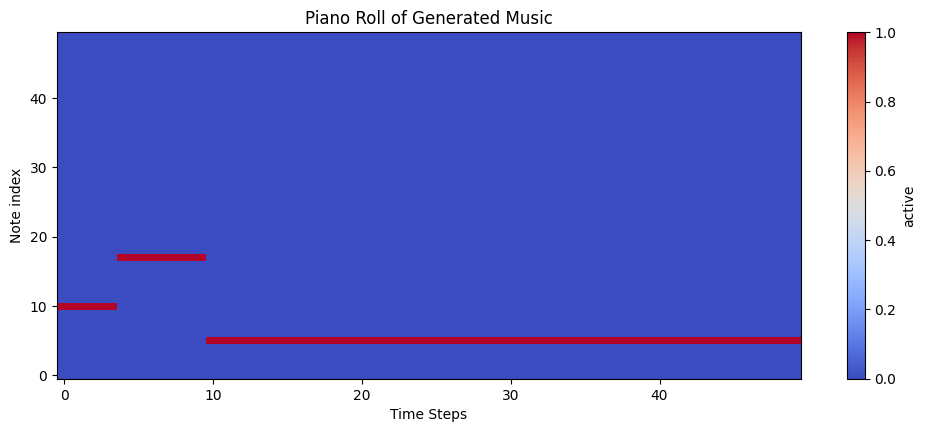

In [13]:
piano_roll = np.zeros((num_notes, len(generated_music)))
for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1   # TODO (Q6): which row is the active note at time t?

plt.figure(figsize=(12,4.5))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower', interpolation='nearest')
plt.colorbar(label='active'); plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps'); plt.ylabel('Note index'); plt.show()

## Task 7 — Analysis

1. **The two Bi-LSTM layers both use `return_sequences=True`. What would break if you set it to `False` on the first layer?**
   If set to `False`, the first layer would only output a single vector of shape `(batch, 256)` representing the last timestep, rather than a sequence of shape `(batch, 29, 256)`. Since the second Bi-LSTM layer requires a sequential sequence input, it would raise a dimensions mismatch error and fail to compile or build.

2. **Why is the first Bi-LSTM's output width 256 when the LSTM has 128 units?**
   A Bidirectional LSTM layer runs two LSTMs: one in the forward direction and one in the backward direction. By default, Keras concatenates their outputs, combining the 128-unit output of the forward LSTM with the 128-unit output of the backward LSTM to yield $128 + 128 = 256$ features.

3. **What does `TimeDistributed(Dense(50))` do that a plain `Dense(50)` would not?**
   `TimeDistributed` explicitly applies the same identical `Dense` weight matrix to each of the 29 timesteps independently. Modern Keras can often apply a plain `Dense` layer across a 3D tensor, but `TimeDistributed` ensures that the sequence structure is strictly preserved and applied per timestep.

4. **You trained on random notes, yet accuracy reaches ~96%. Explain the mechanism.**
   Because of the bidirectional architecture, the backward LSTM reads the sequence from right to left. Since our target $y_t$ is equal to $x_{t+1}$ (the next note), the backward LSTM at time step $t$ can easily peek into the future note $x_{t+1}$ from the input. This causes complete data leakage, making the prediction task trivial.

5. **Why is a bidirectional model a poor choice for autoregressive generation, and what two changes would make this an honest music generator?**
   During true autoregressive generation, future notes do not exist yet, making a backward pass impossible. To make this an honest music generator:
   * Change the Bidirectional LSTMs to standard **Unidirectional (causal) LSTMs**.
   * Retrain on the data so the model is forced to learn only from the historical notes.

In [30]:

import numpy as np
from IPython.display import Audio, display
from scipy.io.wavfile import write

sample_rate = 22050
bpm = 90
beat = 60 / bpm
duration = beat

def piano_note(midi, duration, volume=1.0):

    freq = 440 * (2 ** ((midi - 69) / 12))

    t = np.linspace(
        0, duration,
        int(sample_rate * duration),
        endpoint=False
    )

    sound = (
        np.sin(2*np.pi*freq*t)
        + 0.4*np.sin(4*np.pi*freq*t)
        + 0.2*np.sin(6*np.pi*freq*t)
    )

    envelope = np.exp(-2.5*t)

    return sound * envelope * volume


def bass_note(midi, duration):

    freq = 440 * (2 ** ((midi - 69) / 12))

    t = np.linspace(
        0, duration,
        int(sample_rate * duration),
        endpoint=False
    )

    return 0.6 * np.sin(2*np.pi*freq*t) * np.exp(-1.2*t)


# Dark cinematic chord progression
chords = [
    [45, 52, 57],  # A minor
    [43, 50, 55],  # G major
    [41, 48, 53],  # F major
    [40, 47, 52]   # E minor
]

# Melody generated from your LSTM
scale = [0, 2, 3, 5, 7, 8, 10]

melody = [
    60 + scale[int(n) % 7]
    for n in generated_music
]

audio_parts = []

for i, note in enumerate(melody):

    chord = chords[(i // 10) % 4]

    segment = np.zeros(int(sample_rate * duration))

    # Main piano melody
    segment += piano_note(
        note, duration, 0.8
    )

    # Heavy bass
    segment += bass_note(
        chord[0] - 12, duration
    )

    # Dark piano chord
    for c in chord:

        segment += piano_note(
            c, duration, 0.22
        )

    # Add cinematic intensity
    segment *= 0.8 + 0.6 * i / len(melody)

    audio_parts.append(segment)

# Combine music
final_audio = np.concatenate(audio_parts)

# Normalize
final_audio /= np.max(np.abs(final_audio)) + 1e-8

print("KGF INSPIRED AI CINEMATIC MUSIC")

display(Audio(final_audio, rate=sample_rate))

KGF INSPIRED AI CINEMATIC MUSIC


In [28]:

audio_output = (
    final_audio * 32767
).astype(np.int16)

write(
    "KGF_AI_Piano_Music.wav",
    sample_rate,
    audio_output
)

from google.colab import files

files.download("KGF_AI_Piano_Music.wav")

print("KGF Piano Music Saved!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

KGF Piano Music Saved!


## (Optional) Stretch — make it causal
Copy the model into a new cell, remove **both** `Bidirectional` wrappers (plain `LSTM`), retrain,
and compare the accuracy curve. Explain why the (lower) number is the more honest one.
